<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank sensible a tópico en Wikipedia</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Tópicos definidos con el árbol de categorías de Wikipedia, un PageRank por tópico, consultas como mezcla de tópicos y validación ocultando artículos.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

El PageRank general del notebook 2 da una sola medida de importancia para todos. El **PageRank sensible a tópico**
(Haveliwala, 2002; Leskovec, Rajaraman y Ullman, cap. 5) calcula un vector por tópico: el lector aleatorio, cuando se
teletransporta, salta solo a artículos de ese tópico. Así, un artículo es importante **para un tema**. Una consulta de
un usuario interesado en varios temas se responde combinando los vectores precalculados.

A diferencia de cit-HepPh, donde los tópicos eran comunidades del grafo sin nombre, Wikipedia **sí trae una
clasificación temática**: el árbol de categorías. Los tópicos se definen a partir de las subcategorías de
[*Main topic classifications*](https://en.wikipedia.org/wiki/Category:Main_topic_classifications) (*Science*,
*History*, *Geography*…), y cada artículo hereda los temas de sus categorías. Como en Spotify, un artículo puede
pertenecer a varios tópicos. Al tener etiquetas, la calidad de los vectores se puede **validar** ocultando una parte
de ellas.

### Los datos

- `data/grafo/adyacencia.npz`: la matriz de adyacencia que guardó el notebook 2, con el mapeo índice → `page_id`.
- `data/grafo/nodos`: los artículos con la marca `is_disambig`, para rehacer el grafo de análisis del notebook 2
  (sin páginas de desambiguación).
- `data/grafo/categorias_nodo` y `data/grafo/jerarquia_categorias`: las categorías de cada artículo y las relaciones
  categoría → subcategoría, del notebook 1.
- `data/grafo/puntajes.parquet`: el PageRank general (β = 0.85) del notebook 2, como referencia.

### Contenido

1. **Datos y verificación.**
2. **Tópicos con el árbol de categorías.** Distancias en el árbol, elección de la profundidad y descripción.
3. **PageRank sensible a tópico.** Un vector por tópico, comparación entre tópicos y tópicos representativos.
4. **Validación:** recuperar el tópico de artículos ocultos y proponer tópicos a los artículos sin categoría.
5. **Consulta de usuario** como mezcla de tópicos.
6. **Conclusiones y limitaciones** de la práctica completa.

**Resultados.** Cada paso guarda sus resultados en `data/resultados/03_topic_sensitive/` (vectores en Parquet con `id`
y `title`, tablas en CSV y gráficas en PNG) y actualiza `data/RESUMEN.md`. Los vectores se calculan en `float64`, con
un máximo de 1,000 iteraciones; si no convergen, se guarda el resultado y se anota el residuo final.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
from IPython.display import display

sys.path.insert(0, "..")   # registro.py está en la carpeta Wikipedia/
import registro as reg

NB = "03_topic_sensitive"  # carpeta de resultados: data/resultados/03_topic_sensitive/

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 80)

GRAFO = Path("..") / "data" / "grafo"
ARCHIVO_MATRIZ = GRAFO / "adyacencia.npz"
ARCHIVO_PUNTAJES = GRAFO / "puntajes.parquet"
SEMILLA = 42
BETA = 0.85

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : np.ndarray
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = np.argpartition(-a, k)[:k], np.argpartition(-b, k)[:k]
    comun = len(np.intersect1d(ta, tb))
    return comun / (2 * k - comun)

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos y verificación</span></div>


La matriz de adyacencia se lee del archivo que guardó el notebook 2. Antes de usarla se comprueba que corresponda a
`nodos`: los mismos `page_id` en el mismo orden y los grados por fila y columna iguales a los guardados. Después se
rehace el **grafo de análisis** del notebook 2 (sin páginas de desambiguación) y se comprueba que el PageRank
general guardado sea el estacionario de ese grafo.

Igual que en el notebook 2, los productos matriz-vector se hacen por **bloques de filas en paralelo**.

In [2]:
# Carga de la matriz y su mapeo, verificación contra nodos y grafo de análisis
inicio = time.time()
A = sp.load_npz(ARCHIVO_MATRIZ)
ids = np.load(ARCHIVO_MATRIZ)["ids"]
nodos = pq.read_table(GRAFO / "nodos").to_pandas().sort_values("idx").reset_index(drop=True)
verificacion = pd.Series({
    "Dimensión de A = número de nodos": A.shape == (len(nodos), len(nodos)),
    "Mismos page_id en el mismo orden": np.array_equal(ids, nodos["id"].to_numpy()),
    "Grados de salida iguales": np.array_equal(np.asarray(A.sum(axis=1)).ravel(), nodos["grado_salida"].to_numpy()),
    "Grados de entrada iguales": np.array_equal(np.asarray(A.sum(axis=0)).ravel(), nodos["grado_entrada"].to_numpy()),
}, name="Se cumple").to_frame()
display(verificacion)
assert verificacion["Se cumple"].all()

conserva = ~nodos["is_disambig"].to_numpy()
A_an = A[conserva][:, conserva].tocsr()
del A
nodos_an = nodos[conserva].reset_index(drop=True)
n = len(nodos_an)
k_out = np.asarray(A_an.sum(axis=1)).ravel()
k_in = np.asarray(A_an.sum(axis=0)).ravel()
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)

BLOQUES = 16
POOL = ThreadPoolExecutor(BLOQUES)


def partir(X, bloques=BLOQUES):
    """Divide una matriz CSR en bloques consecutivos de filas (ver notebook 2)."""
    cortes = np.linspace(0, X.shape[0], bloques + 1).astype(int)
    return [X[a:b] for a, b in zip(cortes[:-1], cortes[1:])]


def producto(bloques, x):
    """Calcula X @ x multiplicando en paralelo los bloques de filas de X (ver notebook 2)."""
    return np.concatenate(list(POOL.map(lambda bloque: bloque @ x, bloques)))


A_bloques = partir(A_an)
AT_bloques = partir(A_an.T.tocsr())
m = A_an.nnz
del A_an   # basta con los bloques

puntajes = pd.read_parquet(ARCHIVO_PUNTAJES)
assert np.array_equal(puntajes["id"].to_numpy(), nodos_an["id"].to_numpy())
pr_general = puntajes["pagerank"].to_numpy()
residuo = BETA * producto(AT_bloques, pr_general * inv_k_out)
residuo = np.abs(residuo + (1 - residuo.sum()) / n - pr_general).sum()
if residuo > 1e-9:
    reg.nota(f"03: el PageRank general guardado tiene un residuo de {residuo:.2e} en el grafo de análisis")
print(f"Grafo de análisis: {n:,} artículos y {m:,} enlaces | residuo del PageRank general guardado: {residuo:.1e}")
verificacion.loc["Residuo del PageRank general guardado"] = residuo
reg.registrar_paso("03.1", inicio, [reg.guardar_tabla(verificacion, "01_verificacion", NB)], f"{n:,} artículos y {m:,} enlaces")

,Se cumple
Dimensión de A = número de nodos,True
Mismos page_id en el mismo orden,True
Grados de salida iguales,True
Grados de entrada iguales,True


Grafo de análisis: 6,879,374 artículos y 233,221,445 enlaces | residuo del PageRank general guardado: 6.5e-11


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TÓPICOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Tópicos con el árbol de categorías</span></div>


**El árbol de categorías.** Cada categoría puede tener subcategorías, y la raíz temática de Wikipedia es *Main topic
classifications*. Sus subcategorías son las **raíces de los tópicos**, salvo dos que no son temas: *Lists* (un
formato) y *Main topic articles* (un contenedor de mantenimiento). En rigor no es un árbol sino un grafo dirigido:
una categoría puede tener varias madres y hay ciclos.

**Asignación.** Para cada raíz $T$ se calcula, con una búsqueda en anchura (`shortest_path` no ponderado), la
distancia $d_T(c)$ de la raíz a cada categoría $c$. La distancia de un artículo $i$ a la raíz es
$d_T(i) = 1 + \min_{c \ni i} d_T(c)$, el mínimo sobre sus categorías. El artículo pertenece a los tópicos **más
cercanos**:

$$\text{tópicos}(i) = \{T : d_T(i) = \min_{T'} d_{T'}(i)\}, \qquad \text{si } \min_{T'} d_{T'}(i) \le D.$$

Si hay empate, pertenece a varios. La profundidad máxima $D$ evita caminos muy largos en los que el tema se va
desviando.

**Categorías de mantenimiento.** Las categorías administrativas (*Articles with…*, *Pages using…*, *CS1…*,
*Use dmy dates…*, *Wikipedia…*) no describen el tema, así que se quitan del árbol y de los artículos.

In [3]:
# Grafo de categorías (madre → hija) sin categorías de mantenimiento y distancias desde cada raíz
inicio = time.time()
jerarquia = pq.read_table(GRAFO / "jerarquia_categorias").to_pandas()
cat_art = ds.dataset(GRAFO / "categorias_nodo").to_table().to_pandas()
MANTENIMIENTO = re.compile(
    r"^(Wikipedia|Articles?\b|All articles|Pages?\b|CS1|Webarchive|Use |Short description|Commons|Hidden categories|"
    r"Tracking categories|Container categories|Template|Redirects?\b|User |Stub|Good articles|Featured |Coordinates|"
    r"Accuracy disputes|Orphaned|Dead |AC with|Noindexed|Infobox|Official website|Disambiguation)", re.IGNORECASE)

codigos, nombres = pd.factorize(np.concatenate([jerarquia["categoria"].to_numpy(object), jerarquia["padre"].to_numpy(object),
                                                cat_art["category"].to_numpy(object)]))
nombres = pd.Index(nombres)
n_cat, n_rel = len(nombres), len(jerarquia)
hija, madre, cat_de_art = codigos[:n_rel], codigos[n_rel:2 * n_rel], codigos[2 * n_rel:]
es_mant = np.asarray(nombres.str.match(MANTENIMIENTO), dtype=bool)
ok = ~es_mant[hija] & ~es_mant[madre]
C = sp.csr_matrix((np.ones(ok.sum()), (madre[ok], hija[ok])), shape=(n_cat, n_cat))

META = ["Lists", "Main topic articles"]
hijas_raiz = sorted(nombres[C[nombres.get_loc("Main topic classifications")].indices])
TOPICOS = [t for t in hijas_raiz if t not in META]
K = len(TOPICOS)
t0 = time.perf_counter()
dist_cat = shortest_path(C, method="D", unweighted=True, indices=nombres.get_indexer(TOPICOS)).astype(np.float32)
print(f"Categorías: {n_cat:,} ({es_mant.sum():,} de mantenimiento) | relaciones madre → hija: {ok.sum():,} | "
      f"BFS desde {K} raíces en {time.perf_counter() - t0:.0f} s")
print("Tópicos:", ", ".join(TOPICOS))

# Distancia de cada artículo del grafo de análisis a cada raíz: 1 + mínimo sobre sus categorías
posicion = np.full(nodos["id"].max() + 1, -1, dtype=np.int64)
posicion[nodos_an["id"].to_numpy()] = np.arange(n)
fila_art = posicion[cat_art["id"].to_numpy()]
valida = (fila_art >= 0) & ~es_mant[cat_de_art]
M_art = sp.csr_matrix((np.ones(valida.sum(), dtype=np.float32), (fila_art[valida], cat_de_art[valida])), shape=(n, n_cat))
M_art.sum_duplicates()
sin_categoria = np.diff(M_art.indptr) == 0
dist_art = np.full((n, K), np.inf, dtype=np.float32)
inicio_filas = M_art.indptr[:-1].clip(max=M_art.nnz - 1)
for t in range(K):
    minimo = np.minimum.reduceat(dist_cat[t][M_art.indices], inicio_filas)
    minimo[sin_categoria] = np.inf
    dist_art[:, t] = minimo + 1
d_min = dist_art.min(axis=1)
del cat_art, codigos, hija, madre, cat_de_art, fila_art

Categorías: 2,303,002 (29,528 de mantenimiento) | relaciones madre → hija: 5,023,193 | BFS desde 32 raíces en 14 s
Tópicos: Academic disciplines, Behavior, Communication, Concepts, Culture, Economy, Education, Energy, Engineering, Entities, Food and drink, Geography, Government, Health, History, Humanities, Humans, Information, Knowledge, Language, Law, Life, Mass media, Mathematics, Philosophy, Politics, Religion, Science, Society, Technology, Time, Universe


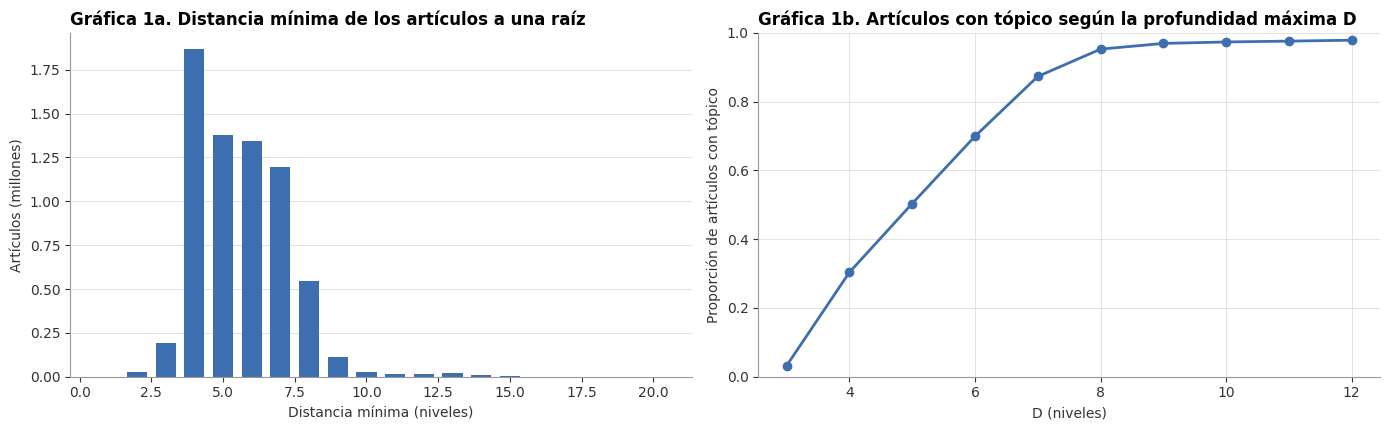

Artículos sin categorías temáticas: 76,982 (1.12 %) | con categorías pero sin camino a ninguna raíz: 36,564


,cobertura,tópicos por artículo,tópico mayor
D,,,
3,3.2%,1.31,8.8%
4,30.4%,1.28,58.5%
5,50.4%,1.51,41.1%
6,69.9%,1.66,33.5%
7,87.3%,1.74,31.4%
8,95.3%,1.80,29.6%
9,96.9%,1.81,29.3%
10,97.3%,1.81,29.2%
11,97.6%,1.81,29.1%


In [4]:
# Gráfica 1. Profundidad mínima de los artículos y cobertura según la profundidad máxima D
alcanzable = np.isfinite(d_min)
prof = pd.Series(d_min[alcanzable]).value_counts().sort_index()
filas = []
for D in range(3, 13):
    pert = (dist_art == d_min[:, None]) & (d_min[:, None] <= D)
    con = pert.any(axis=1)
    filas.append({"D": D, "cobertura": con.mean(), "tópicos por artículo": pert[con].sum(axis=1).mean(),
                  "tópico mayor": pert.sum(axis=0).max() / con.sum()})
cobertura = pd.DataFrame(filas).set_index("D")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
ax1.bar(prof.index, prof.to_numpy() / 1e6, color=AZUL, width=0.7)
estilo_ejes(ax1, "Gráfica 1a. Distancia mínima de los artículos a una raíz", "Distancia mínima (niveles)",
            "Artículos (millones)")
ax2.plot(cobertura.index, cobertura["cobertura"], color=AZUL, marker="o", linewidth=2)
ax2.set_ylim(0, 1)
estilo_ejes(ax2, "Gráfica 1b. Artículos con tópico según la profundidad máxima D", "D (niveles)",
            "Proporción de artículos con tópico", rejilla="both")
plt.tight_layout()
archivo_g1 = reg.guardar_figura(fig, "grafica_01_profundidad_y_cobertura", NB)
plt.show()
print(f"Artículos sin categorías temáticas: {sin_categoria.sum():,} ({pct(sin_categoria.mean())}) | con categorías "
      f"pero sin camino a ninguna raíz: {(~sin_categoria & ~alcanzable).sum():,}")
display(cobertura.style.format({"cobertura": "{:.1%}", "tópicos por artículo": "{:.2f}", "tópico mayor": "{:.1%}"}))

**Decisión: $D = 8$.** Con $D = 8$ tiene tópico el **95.3 %** de los artículos del grafo de análisis; con $D = 7$ sería el
**87.3 %** y con $D = 9$ el **96.9 %**. A partir de 8 la curva se aplana (Gráfica 1b): casi no se gana cobertura, y los
caminos más largos se desvían cada vez más del tema. El número de tópicos por artículo también se estabiliza en
**1.80**.

Al resto le faltan categorías o caminos:
- **76,982** artículos (**1.12 %**) no tienen categorías temáticas;
- **36,564** tienen categorías, pero sin camino a ninguna raíz;
- los demás están a más de 8 niveles.

In [5]:
# Pertenencia de los artículos a los tópicos con D = 8 y descripción de cada tópico
D = 8
pertenencia = (dist_art == d_min[:, None]) & (d_min[:, None] <= D)
con_topico = pertenencia.any(axis=1)
tam_topico = pertenencia.sum(axis=0)
del dist_art, M_art

# Cohesión: proporción de los enlaces que salen de los artículos del tópico y llegan a artículos del tópico
P = pertenencia.astype(np.float32)
AP = producto(A_bloques, P)          # AP[i, t] = enlaces de i hacia artículos de t
cohesion = (P * AP).sum(axis=0) / (P * k_out[:, None]).sum(axis=0)
del AP

descripcion = pd.DataFrame({
    "artículos": tam_topico, "% del grafo": tam_topico / n,
    "exclusivos (un solo tópico)": (pertenencia & (pertenencia.sum(axis=1) == 1)[:, None]).sum(axis=0) / tam_topico,
    "cohesión": cohesion,
    "más enlazados": [", ".join(nodos_an.loc[np.where(pertenencia[:, t])[0][np.argsort(-k_in[pertenencia[:, t]])[:3]], "title"])
                      for t in range(K)],
}, index=pd.Index(TOPICOS, name="tópico")).sort_values("artículos", ascending=False)
print(f"Artículos con tópico: {con_topico.sum():,} ({pct(con_topico.mean())}) | tópicos por artículo: media "
      f"{pertenencia[con_topico].sum(axis=1).mean():.2f}, máximo {pertenencia.sum(axis=1).max()}")
display(descripcion.style.format({"artículos": "{:,}", "% del grafo": "{:.2%}", "exclusivos (un solo tópico)": "{:.1%}",
                                  "cohesión": "{:.1%}"}))

Artículos con tópico: 6,553,675 (95.27 %) | tópicos por artículo: media 1.80, máximo 17


,artículos,% del grafo,exclusivos (un solo tópico),cohesión,más enlazados
tópico,,,,,
Humans,"1,942,164",28.23%,65.8%,21.0%,"Village, Moth, Los Angeles Times"
Culture,"1,327,842",19.30%,21.6%,30.8%,"United States, AllMusic, Midfielder"
Geography,"1,032,657",15.01%,40.8%,36.3%,"United States, Germany, U.S. state"
Society,"936,927",13.62%,10.5%,22.7%,"United States, France, Germany"
Mass media,"850,504",12.36%,42.4%,43.3%,"The New York Times, AllMusic, YouTube"
Government,"816,562",11.87%,32.9%,37.2%,"United States, France, Germany"
History,"701,974",10.20%,23.6%,19.6%,"India, Catholic Church, China"
Humanities,"449,669",6.54%,14.7%,19.6%,"Romanization, Europe, Race and ethnicity in the United States census"
Technology,"373,999",5.44%,20.3%,26.6%,"World War II, New York City, London"


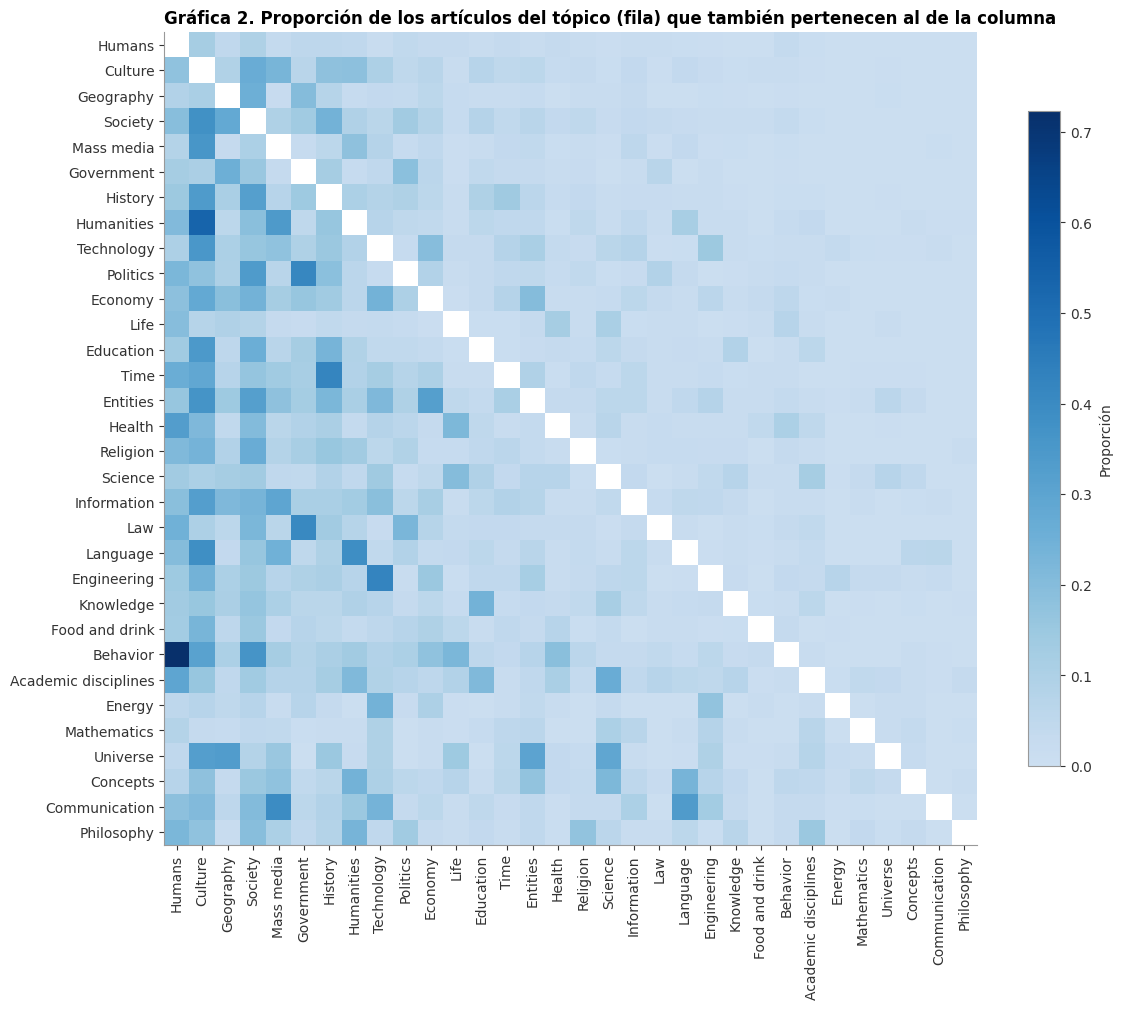

In [6]:
# Gráfica 2. Traslape entre tópicos: proporción de los artículos del tópico fila que también están en el tópico columna
orden = list(descripcion.index)
indice_topico = {t: i for i, t in enumerate(TOPICOS)}
Pb = pertenencia[:, [indice_topico[t] for t in orden]].astype(np.float32)
coocurrencia = Pb.T @ Pb
proporcion = coocurrencia / np.diag(coocurrencia)[:, None]
np.fill_diagonal(proporcion, np.nan)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(proporcion, cmap=CMAP_SEC, vmin=0, vmax=np.nanmax(proporcion))
ax.set_xticks(range(K), labels=orden, rotation=90)
ax.set_yticks(range(K), labels=orden)
estilo_ejes(ax, "Gráfica 2. Proporción de los artículos del tópico (fila) que también pertenecen al de la columna",
            rejilla=None)
fig.colorbar(im, ax=ax, shrink=0.8, label="Proporción")
plt.tight_layout()
archivo_g2 = reg.guardar_figura(fig, "grafica_02_traslape_topicos", NB)
plt.show()
del Pb

topicos_de = np.array(["; ".join(np.array(TOPICOS)[fila]) for fila in pertenencia])
tabla_pertenencia = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"], "topicos": topicos_de,
                                  "distancia_minima": d_min})
reg.registrar_paso("03.2", inicio, [
    reg.guardar_parquet(tabla_pertenencia, "02_pertenencia", NB), reg.guardar_tabla(cobertura, "02_cobertura_por_D", NB),
    reg.guardar_tabla(descripcion, "02_descripcion_topicos", NB),
    reg.guardar_tabla(pd.DataFrame(proporcion, index=orden, columns=orden), "02_traslape_topicos", NB), archivo_g1, archivo_g2,
], f"{K} tópicos, D = {D}, {pct(con_topico.mean())} de los artículos con tópico")
del topicos_de, tabla_pertenencia

**Observaciones: tópicos**

- **Los tópicos.** Son **32**, que cubren **6,553,675** artículos (**95.27 %**), con **1.80** tópicos por artículo en
  promedio y hasta **17**.
- **Son muy desiguales.** *Humans* tiene **1,942,164** artículos (**28.23 %**), sobre todo biografías.
  *Culture* tiene el **19.30 %** y *Geography* el **15.01 %**. En el otro extremo, *Philosophy* tiene
  **17,763** (**0.26 %**) y *Communication* **25,673**.
- **La pertenencia múltiple es lo normal.** Solo el **65.8 %** de los artículos de *Humans* es exclusivo de ese
  tópico, y en *Society* y *Behavior* apenas el **10.5 %** y el **7.4 %**. Los temas generales comparten casi todos
  sus artículos con otros (Gráfica 2).
- **La cohesión es baja.** Va del **4.9 %** (*Communication*) al **46.6 %** (*Mathematics*), con *Mass media* en
  **43.3 %**. En cit-HepPh, con tópicos de Louvain, iba del 68 % al 87 %. Las categorías de Wikipedia no se
  construyeron a partir de los enlaces, así que no forman comunidades del grafo.
- **El árbol de categorías tiene deriva.** Entre los más enlazados de cada tópico aparecen artículos ajenos al tema:
  *Village* y *Moth* en *Humans*, *Watt* y *Limestone* en *Universe*, *Belgrade* en *Mathematics*,
  *St. Louis Cardinals* en *Food and drink*. Es lo que pasa con un grafo de categorías con varias madres y
  ciclos: un camino de 8 niveles puede pasar por temas muy distintos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PageRank sensible a tópico</span></div>


Para cada tópico $T$ con conjunto de artículos $S$, el vector $r_S$ es el estacionario de

$$r = \beta M r + (1 - \beta)\,\frac{e_S}{|S|},$$

donde $e_S$ vale 1 en los artículos de $S$ y 0 en los demás. La única diferencia con el PageRank general es **a
dónde se teletransporta** el lector: en lugar de saltar a cualquier artículo, salta a uno del tópico.

**Nodos colgantes.** Como en el notebook 2, la probabilidad que llega a un colgante se reparte según el vector de
teletransportación, es decir, **regresa a $S$**. Así el vector entero queda "anclado" al tópico. Es la misma opción
que en cit-HepPh (`personalization` con `dangling=None`).

**Todos los tópicos a la vez.** Los $K$ vectores se calculan juntos con el método de potencias sobre una matriz
$R \in \mathbb{R}^{n \times K}$, una columna por tópico: cada iteración es un solo producto de $A^\top$ por una matriz
densa, que aprovecha mejor la memoria que $K$ productos matriz-vector. Se itera hasta que **todas** las columnas
cumplan $\lVert r_{t+1} - r_t \rVert_1 < 10^{-8}$, con un máximo de 1,000 iteraciones. Es una tolerancia menos
estricta que la del notebook 2, pero el error en cada puntaje es mucho menor que las diferencias entre artículos.

In [7]:
# Un vector de PageRank por tópico, todos a la vez (método de potencias por bloques)
inicio = time.time()
def pagerank_topicos(V, beta=BETA, tol=1e-8, max_iter=1000):
    """
    Calcula un PageRank por columna de V, con teletransportación (y colgantes) según cada columna.

    Parámetros
    ----------
    V : np.ndarray
        Matriz (n, K) no negativa: la columna t es el vector de teletransportación del tópico t.
    beta : float
        Probabilidad de seguir un enlace.
    tol : float
        Criterio de paro: máximo sobre las columnas de ‖r_{t+1} − r_t‖₁.
    max_iter : int
        Número máximo de iteraciones.

    Retorna
    -------
    tuple of (np.ndarray, int)
        Matriz (n, K) de PageRank (cada columna suma 1) e iteraciones. Si no converge, devuelve la última matriz y
        max_iter, y anota el residuo final en RESUMEN.md.
    """
    V = V / V.sum(axis=0, dtype=np.float64)
    R = np.full(V.shape, 1 / V.shape[0])
    for iteracion in range(1, max_iter + 1):
        nuevo = beta * producto(AT_bloques, R * inv_k_out[:, None])
        nuevo += (1 - nuevo.sum(axis=0)) * V
        error = np.abs(nuevo - R).sum(axis=0).max()
        R = nuevo
        if error < tol:
            return R, iteracion
    reg.nota(f"PageRank por tópico ({V.shape[1]} columnas) no convergió en {max_iter} iteraciones; residuo final "
             f"máx ‖r_t+1 − r_t‖₁ = {error:.2e}")
    return R, max_iter


t0 = time.perf_counter()
TSPR, it_tspr = pagerank_topicos(P)
segundos_tspr = time.perf_counter() - t0
assert np.allclose(TSPR.sum(axis=0), 1)
print(f"{K} vectores en {it_tspr} iteraciones y {segundos_tspr / 60:.1f} min | todos suman 1")

top100 = np.argsort(-TSPR, axis=0)[:100]
masa = pd.DataFrame({
    "artículos": tam_topico,
    "masa en el propio tópico": (TSPR * P).sum(axis=0),
    "proporción en el grafo": tam_topico / n,
    "top-100 general en el tópico": P[np.argsort(-pr_general)[:100]].mean(axis=0),
    "top-100 del tópico en el tópico": [P[top100[:, t], t].mean() for t in range(K)],
}, index=pd.Index(TOPICOS, name="tópico")).loc[orden]
display(masa.style.format({"artículos": "{:,}", "masa en el propio tópico": "{:.1%}", "proporción en el grafo": "{:.2%}",
                           "top-100 general en el tópico": "{:.0%}", "top-100 del tópico en el tópico": "{:.0%}"}))
vectores_tspr = pd.DataFrame(TSPR, columns=TOPICOS)
vectores_tspr.insert(0, "title", nodos_an["title"].to_numpy())
vectores_tspr.insert(0, "id", nodos_an["id"].to_numpy())
reg.registrar_paso("03.3", inicio, [reg.guardar_parquet(vectores_tspr, "03_pagerank_por_topico", NB),
                                    reg.guardar_tabla(masa, "03_masa_y_pureza", NB)],
                   f"{K} vectores en {it_tspr} iteraciones ({segundos_tspr / 60:.1f} min)")
del vectores_tspr

32 vectores en 62 iteraciones y 12.1 min | todos suman 1


,artículos,masa en el propio tópico,proporción en el grafo,top-100 general en el tópico,top-100 del tópico en el tópico
tópico,,,,,
Humans,"1,942,164",30.1%,28.23%,9%,9%
Culture,"1,327,842",35.1%,19.30%,13%,26%
Geography,"1,032,657",36.0%,15.01%,20%,31%
Society,"936,927",33.0%,13.62%,35%,38%
Mass media,"850,504",37.3%,12.36%,15%,42%
Government,"816,562",37.0%,11.87%,26%,32%
History,"701,974",27.7%,10.20%,9%,10%
Humanities,"449,669",25.8%,6.54%,2%,7%
Technology,"373,999",28.7%,5.44%,7%,16%


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Comparación entre tópicos y con el PageRank general</span></div>


Con 32 tópicos, una tabla de top-k por tópico sería ilegible. La comparación se hace con un **mapa de calor del
Jaccard del top-100** entre cada par de vectores, incluido el PageRank general. El detalle de los top-k queda para
cuatro tópicos representativos (sección 3.2).

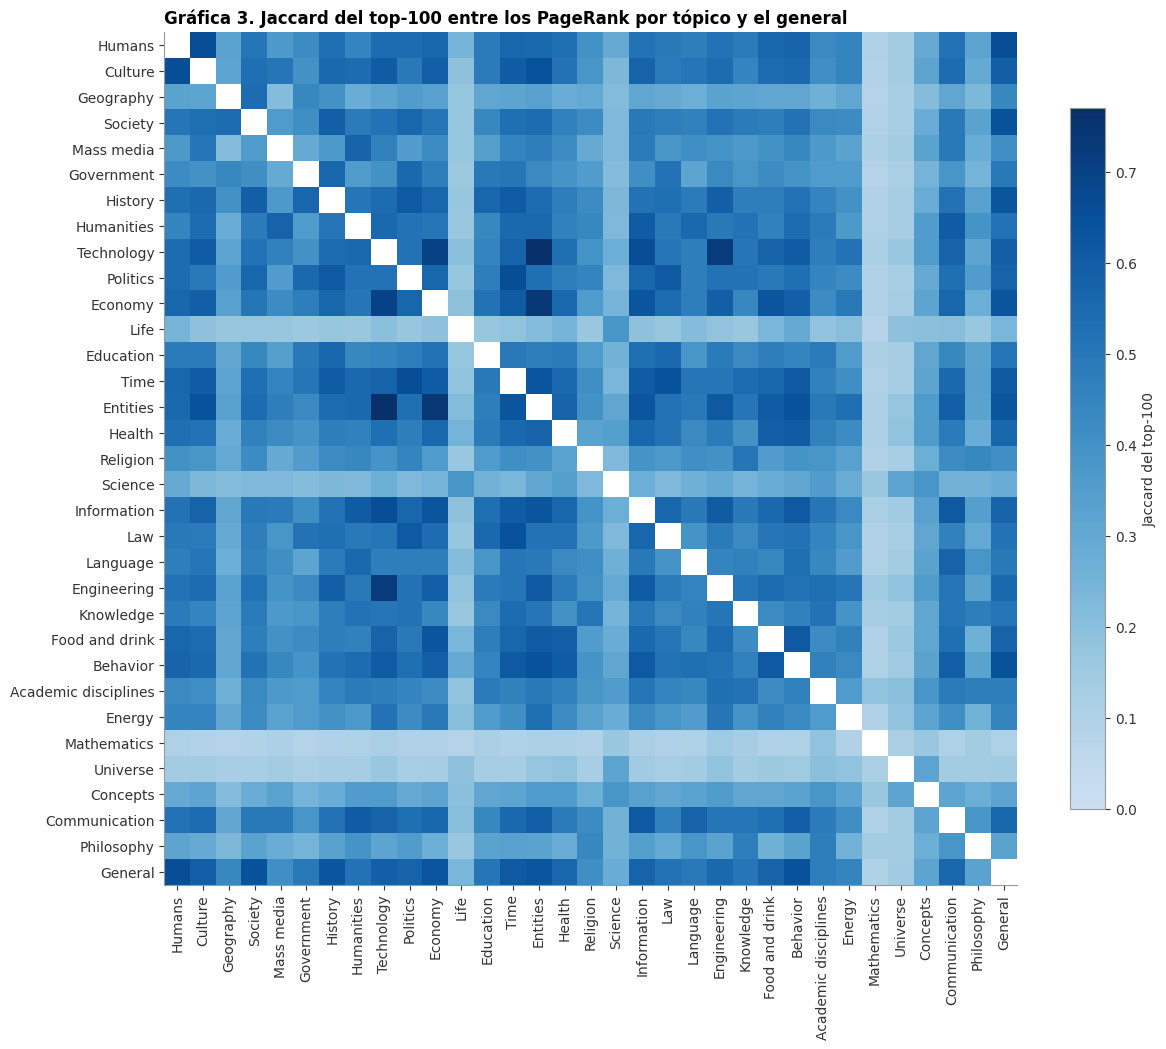

Jaccard con el general: mediana 0.515, mínimo 0.105 (Mathematics), máximo 0.653 (Humans)
Par de tópicos más parecido: Technology y Entities (0.770)


In [8]:
# Gráfica 3. Jaccard del top-100 entre los vectores de tópico y el PageRank general
inicio = time.time()
etiquetas = orden + ["General"]
vectores = {t: TSPR[:, indice_topico[t]] for t in orden} | {"General": pr_general}
J = pd.DataFrame([[jaccard_top(vectores[a], vectores[b], 100) for b in etiquetas] for a in etiquetas],
                 index=etiquetas, columns=etiquetas)
fig, ax = plt.subplots(figsize=(12.5, 10.5))
mascara = np.eye(len(etiquetas), dtype=bool)
im = ax.imshow(np.where(mascara, np.nan, J.to_numpy()), cmap=CMAP_SEC, vmin=0, vmax=np.nanmax(J.where(~mascara)))
ax.set_xticks(range(len(etiquetas)), labels=etiquetas, rotation=90)
ax.set_yticks(range(len(etiquetas)), labels=etiquetas)
estilo_ejes(ax, "Gráfica 3. Jaccard del top-100 entre los PageRank por tópico y el general", rejilla=None)
fig.colorbar(im, ax=ax, shrink=0.8, label="Jaccard del top-100")
plt.tight_layout()
archivo_g3 = reg.guardar_figura(fig, "grafica_03_jaccard_topicos", NB)
plt.show()
fuera = J.where(~mascara)
print(f"Jaccard con el general: mediana {fuera['General'].median():.3f}, mínimo {fuera['General'].min():.3f} "
      f"({fuera['General'].idxmin()}), máximo {fuera['General'].max():.3f} ({fuera['General'].idxmax()})")
par = fuera.drop(index="General", columns="General").stack().idxmax()
print(f"Par de tópicos más parecido: {par[0]} y {par[1]} ({fuera.loc[par]:.3f})")
reg.registrar_paso("03.3.1", inicio, [reg.guardar_tabla(J, "03_1_jaccard_top100", NB), archivo_g3],
                   f"Jaccard mediano con el general {fuera['General'].median():.3f}")

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.2 Cuatro tópicos representativos</span></div>


Se eligen con criterios objetivos, para no escoger a mano los que "se ven bien":

- el **más grande**;
- el **más pequeño**;
- el **más cohesivo** (mayor proporción de enlaces internos);
- el **más distinto del PageRank general** (menor Jaccard del top-100 con el general).

Si un tópico cumple dos criterios, se toma el siguiente en la lista del segundo criterio. Para cada uno se muestran sus
10 artículos principales, su lugar en el PageRank general y si pertenecen al tópico.

In [9]:
# Selección de los tópicos representativos y sus top-10
inicio = time.time()
lugar_general = pd.Series(pr_general).rank(ascending=False, method="min").astype(int).to_numpy()
candidatos = [("más grande", list(descripcion.index)),
              ("más pequeño", list(descripcion.index[::-1])),
              ("más cohesivo", list(descripcion["cohesión"].sort_values(ascending=False).index)),
              ("más distinto del general", list(fuera["General"].drop("General").sort_values().index))]
representativos = {}
for criterio, lista in candidatos:
    representativos[next(t for t in lista if t not in representativos)] = criterio

archivos_rep = []
for t, criterio in representativos.items():
    c = indice_topico[t]
    top = np.argsort(-TSPR[:, c])[:10]
    print(f"{t} ({criterio}): {tam_topico[c]:,} artículos")
    tabla = pd.DataFrame({"artículo": nodos_an.loc[top, "title"].to_numpy(), "PageRank del tópico": TSPR[top, c],
                          "en el tópico": np.where(pertenencia[top, c], "sí", "no"),
                          "lugar general": lugar_general[top]}, index=pd.RangeIndex(1, 11, name="lugar"))
    display(tabla.style.format({"PageRank del tópico": "{:.2e}", "lugar general": "{:,}"}))
    archivos_rep.append(reg.guardar_tabla(tabla, f"03_2_top10_{t.lower().replace(' ', '_')}", NB))

Humans (más grande): 1,942,164 artículos


,artículo,PageRank del tópico,en el tópico,lugar general
lugar,,,,
1,Association football,1.44e-03,no,4
2,The New York Times,9.00e-04,no,2
3,United States,8.72e-04,no,1
4,World War II,7.77e-04,no,3
5,Moth,5.84e-04,sí,18
6,New York City,5.32e-04,no,7
7,The Guardian,5.03e-04,no,8
8,United Kingdom,4.97e-04,no,6
9,London,4.82e-04,no,10


Philosophy (más pequeño): 17,763 artículos


,artículo,PageRank del tópico,en el tópico,lugar general
lugar,,,,
1,Philosophy,1.62e-03,sí,259
2,The New York Times,9.34e-04,no,2
3,United States,8.63e-04,no,1
4,Western philosophy,7.95e-04,sí,"3,032"
5,World War II,7.85e-04,no,3
6,Oxford University Press,7.39e-04,no,17
7,Contemporary philosophy,7.10e-04,sí,"7,007"
8,Latin,5.92e-04,no,20
9,Academic journal,5.79e-04,no,47


Mathematics (más cohesivo): 48,835 artículos


,artículo,PageRank del tópico,en el tópico,lugar general
lugar,,,,
1,Mathematics,3.36e-03,sí,154
2,Springer Science+Business Media,1.10e-03,no,257
3,Real number,9.46e-04,sí,"1,368"
4,Cambridge University Press,8.45e-04,no,40
5,United States,7.75e-04,no,1
6,American Mathematical Society,7.63e-04,sí,"3,977"
7,Mathematician,7.32e-04,sí,"2,092"
8,Academic journal,7.12e-04,no,47
9,Integer,7.08e-04,sí,"2,002"


Universe (más distinto del general): 39,497 artículos


,artículo,PageRank del tópico,en el tópico,lugar general
lugar,,,,
1,Tennis,1.41e-03,no,289
2,Chemical formula,1.13e-03,no,"1,751"
3,Gene,7.78e-04,no,182
4,Protein,7.37e-04,sí,151
5,Genus,7.16e-04,no,37
6,United States,7.07e-04,no,1
7,Clay court,6.66e-04,sí,"9,092"
8,NASA,6.59e-04,no,225
9,Cambridge University Press,6.40e-04,no,40


In [10]:
# Artículos que más suben al pasar del PageRank general al de su propio tópico (dentro del top-100 del tópico)
filas_suben = []
for t in representativos:
    c = indice_topico[t]
    lugar_t = pd.Series(TSPR[:, c]).rank(ascending=False, method="min").astype(int).to_numpy()
    propios = [i for i in np.argsort(-TSPR[:, c])[:100] if pertenencia[i, c]]
    mejor = max(propios, key=lambda i: lugar_general[i] - lugar_t[i])
    filas_suben.append({"tópico": t, "artículo": nodos_an.loc[mejor, "title"], "k_in": k_in[mejor],
                        "lugar en el tópico": lugar_t[mejor], "lugar general": lugar_general[mejor]})
tabla_suben = pd.DataFrame(filas_suben).set_index("tópico")
display(tabla_suben.style.format({"k_in": "{:,}", "lugar general": "{:,}"}))
reg.registrar_paso("03.3.2", inicio, archivos_rep + [reg.guardar_tabla(tabla_suben, "03_2_los_que_mas_suben", NB)],
                   "; ".join(f"{t} ({c})" for t, c in representativos.items()))

,artículo,k_in,lugar en el tópico,lugar general
tópico,,,,
Humans,Doctor of Philosophy,"39,400.0",73,136
Philosophy,Continental philosophy,892.0,71,"16,502"
Mathematics,Category (mathematics),659.0,76,"15,298"
Universe,Lunar craters,"1,486.0",45,"30,862"


**Observaciones: PageRank sensible a tópico**

- **Convergencia.** Los **32** vectores convergen juntos en **62** iteraciones (**12.1** min) y todos suman 1.
- **Los vectores quedan poco anclados a su tópico.** La masa en el propio tópico va del **17.3 %**
  (*Communication*) al **39.2 %** (*Mathematics*). En cit-HepPh iba del 66.9 % al 87.4 %. Hay un enriquecimiento:
  *Philosophy* tiene el 0.26 % de los artículos y recibe el **20.1 %** de su vector. Pero la mayor parte de la masa
  se va fuera.
- **La pureza del top-100 es baja.** Va del **3 %** (*Communication*) al **62 %** (*Mathematics*); en *Humans* es del
  **9 %**.
- **Por qué.** El grafo es casi una sola componente (SCC del **94.7 %**) y todos los temas enlazan al núcleo general:
  países, *United States*, *The New York Times*, *Oxford University Press*. Con $\beta$ = 0.85 el lector sigue en promedio $\beta / (1 - \beta) \approx$ 5.7 enlaces antes de teletransportarse, suficientes para llegar a ese núcleo. Además, la pertenencia
  a los tópicos tiene ruido (sección 2).
- **Comparación entre tópicos (Gráfica 3).**
  - El Jaccard del top-100 con el PageRank general tiene una mediana de **0.515**. Va de **0.105**
    (*Mathematics*) a **0.653** (*Humans*).
  - El par de tópicos más parecido es *Technology* y *Entities* (**0.770**).
  - *Mathematics*, *Universe*, *Life* y *Science* son los más distintos de todos: sus filas son las más claras.
- **Los cuatro representativos.**
  - *Humans* (el más grande): su top-10 es casi el general; solo *Moth* es del tópico.
  - *Philosophy* (el más pequeño): pone arriba a *Philosophy*, *Western philosophy* y *Contemporary philosophy*,
    entre medios y editoriales.
  - *Mathematics* (el más cohesivo): es el más limpio. Aparecen *Mathematics* (lugar general **154**),
    *Real number*, *American Mathematical Society*, *Mathematician* e *Integer*, junto a las editoriales
    científicas (*Springer*, *Cambridge University Press*).
  - *Universe* (el más distinto del general): muestra la deriva. Arriba están *Tennis* y *Clay court* (que llega a
    *Universe* por una cadena de categorías), junto a *Chemical formula*, *Gene*, *Protein* y *NASA*.
- **Sí recupera artículos que el PageRank general entierra.**
  - *Continental philosophy* sube del lugar **16,502** al **71** en *Philosophy*.
  - *Category (mathematics)* sube del **15,298** al **76** en *Mathematics*.
  - *Lunar craters* sube del **30,862** al **45** en *Universe*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · VALIDACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Validación: ¿el PageRank por tópico recupera el tema de un artículo?</span></div>


Si el PageRank de un tópico mide la cercanía de cada artículo con ese tema, el tópico con mayor puntaje debería
coincidir con el tema real del artículo. Para evaluarlo sin fuga de información, como en Spotify:

1. Se **ocultan** el 20 % de los artículos con tópico (semilla 42): se quitan de los conjuntos de teletransportación.
2. Se recalculan los 32 vectores con los conjuntos reducidos.
3. Para cada artículo oculto se predice $\arg\max_T r_T(i)$. Es acierto si el tópico predicho es **uno de** sus
   tópicos reales.

Se compara con dos líneas base:

- **tópico mayor:** predecir siempre el tópico con más artículos;
- **voto de vecinos:** el tópico más frecuente entre los artículos etiquetados que lo enlazan o a los que enlaza.

In [11]:
# Ocultar el 20 % de los artículos con tópico y recalcular los vectores
inicio = time.time()
rng = np.random.default_rng(SEMILLA)
etiquetados = np.where(con_topico)[0]
ocultos = rng.choice(etiquetados, size=int(0.2 * len(etiquetados)), replace=False)
P_entreno = P.copy()
P_entreno[ocultos] = 0
t0 = time.perf_counter()
TSPR_entreno, it_entreno = pagerank_topicos(P_entreno)
print(f"Vectores con {len(ocultos):,} artículos ocultos: {it_entreno} iteraciones en {(time.perf_counter() - t0) / 60:.1f} min")

prediccion = TSPR_entreno[ocultos].argmax(axis=1)
acierto = pertenencia[ocultos, prediccion]

# Línea base 1: el tópico más grande del entrenamiento
mayor = P_entreno.sum(axis=0).argmax()
acierto_mayor = pertenencia[ocultos, mayor]

# Línea base 2: voto de los vecinos etiquetados (enlaces de entrada y de salida)
votos = (producto(A_bloques, P_entreno) + producto(AT_bloques, P_entreno))[ocultos]
con_vecinos = votos.sum(axis=1) > 0
acierto_vecinos = con_vecinos & pertenencia[ocultos, votos.argmax(axis=1)]

validacion = pd.DataFrame({
    "PageRank por tópico": [acierto.mean(), acierto[con_vecinos].mean(), acierto[~con_vecinos].mean()],
    f"tópico mayor ({TOPICOS[mayor]})": [acierto_mayor.mean(), acierto_mayor[con_vecinos].mean(),
                                         acierto_mayor[~con_vecinos].mean()],
    "voto de vecinos": [acierto_vecinos.mean(), acierto_vecinos[con_vecinos].mean(), np.nan],
}, index=[f"todos los ocultos ({len(ocultos):,})", f"con algún vecino etiquetado ({con_vecinos.sum():,})",
          f"sin vecinos etiquetados ({(~con_vecinos).sum():,})"])
display(validacion.style.format("{:.1%}", na_rep="—"))

Vectores con 1,310,735 artículos ocultos: 62 iteraciones en 11.9 min


,PageRank por tópico,tópico mayor (Humans),voto de vecinos
"todos los ocultos (1,310,735)",41.1%,29.6%,48.3%
"con algún vecino etiquetado (1,309,811)",41.1%,29.6%,48.3%
sin vecinos etiquetados (924),27.1%,21.8%,—


In [12]:
# Precisión y exhaustividad por tópico de la predicción con PageRank por tópico
por_topico = pd.DataFrame({
    "artículos ocultos del tópico": pertenencia[ocultos].sum(axis=0),
    "predichos como el tópico": np.bincount(prediccion, minlength=K),
    "precisión": [acierto[prediccion == t].mean() if (prediccion == t).any() else np.nan for t in range(K)],
    "exhaustividad": [(prediccion[pertenencia[ocultos, t]] == t).mean() for t in range(K)],
}, index=pd.Index(TOPICOS, name="tópico")).loc[orden]
display(por_topico.style.format({"artículos ocultos del tópico": "{:,}", "predichos como el tópico": "{:,}",
                                 "precisión": "{:.1%}", "exhaustividad": "{:.1%}"}, na_rep="—"))
predicciones = pd.DataFrame({"id": nodos_an.loc[ocultos, "id"].to_numpy(), "title": nodos_an.loc[ocultos, "title"].to_numpy(),
                             "topicos_reales": ["; ".join(np.array(TOPICOS)[pertenencia[i]]) for i in ocultos],
                             "prediccion_pagerank": np.array(TOPICOS)[prediccion], "acierto_pagerank": acierto,
                             "acierto_vecinos": acierto_vecinos})
reg.registrar_paso("03.4", inicio, [reg.guardar_tabla(validacion, "04_validacion", NB),
                                    reg.guardar_tabla(por_topico, "04_validacion_por_topico", NB),
                                    reg.guardar_parquet(predicciones, "04_predicciones_ocultos", NB)],
                   f"acierto PageRank por tópico {acierto.mean():.1%}, voto de vecinos {acierto_vecinos.mean():.1%}")
del TSPR_entreno, P_entreno, votos, predicciones

,artículos ocultos del tópico,predichos como el tópico,precisión,exhaustividad
tópico,,,,
Humans,"387,346","77,412",65.2%,13.0%
Culture,"265,866","56,350",42.8%,9.1%
Geography,"206,837","79,499",82.7%,31.8%
Society,"187,380","22,140",64.9%,7.7%
Mass media,"170,088","129,446",63.7%,48.5%
Government,"163,555","59,504",63.4%,23.1%
History,"140,475","34,005",43.0%,10.4%
Humanities,"89,849","43,252",46.2%,22.2%
Technology,"74,791","25,039",50.8%,17.0%


**Observaciones: validación**

- **Los datos de la prueba.** Se ocultan **1,310,735** artículos y los vectores se recalculan en **62** iteraciones
  (**11.9** min).
- **El PageRank por tópico supera a la línea base, pero no al voto de vecinos.**
  - Acierta el **41.1 %**.
  - Predecir siempre *Humans* acierta el **29.6 %**.
  - El voto de los vecinos acierta el **48.3 %**.
  - Casi todos los ocultos tienen algún vecino etiquetado (**1,309,811**). Entre los **924** que no, el PageRank por
    tópico acierta el **27.1 %**, contra **21.8 %** de la línea base.
- **Diferencia con Spotify.** Allí el PageRank por tópico y el voto de vecinos empataban (60.5 % y 60.8 %). En
  Wikipedia los enlaces directos son muy informativos, porque un artículo enlaza a los de su tema. Los caminos de
  varios pasos, en cambio, se desvían al núcleo general (sección 3).
- **$\arg\max_T r_T$ favorece a los tópicos pequeños.** Como cada vector suma 1, los de tópicos pequeños concentran su
  masa en menos artículos y dan puntajes más altos.
  - *Academic disciplines* se predice **64,149** veces para **15,624** artículos ocultos, con una precisión del
    **3.9 %**.
  - *Philosophy* se predice **19,843** veces para **3,558**.
  - Los tópicos grandes casi no se predicen: la exhaustividad de *Humans* es del **13.0 %** y la de *Society* del
    **7.7 %**.
  - Los mejores son *Geography* (precisión **82.7 %**), *Humans* (**65.2 %**) y *Mass media* (**63.7 %**, con
    exhaustividad **48.5 %**).
- **Cómo se mejoraría.** Normalizando el puntaje de cada tópico antes del $\arg\max$, por ejemplo con el percentil de
  $r_T(i)$ dentro de su vector o con $r_T(i) / r(i)$ relativo a la media del tópico. No se hizo, para seguir el
  mismo procedimiento que en Spotify.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · VALIDACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4.1 Tópico propuesto para los artículos sin tópico</span></div>


Con los vectores calculados con todos los artículos etiquetados, se propone para cada artículo sin tópico el de mayor
PageRank, $\arg\max_T r_T(i)$, y se reporta qué tan marcada es la preferencia con la afinidad $r_T(i) / r(i)$
respecto al PageRank general.

In [13]:
# Tópico propuesto para los artículos sin tópico, con su afinidad r_T / r_general
inicio = time.time()
sin_topico = np.where(~con_topico)[0]
propuesto = TSPR[sin_topico].argmax(axis=1)
afinidad = TSPR[sin_topico, propuesto] / pr_general[sin_topico]
propuestas = pd.DataFrame({"artículo": nodos_an.loc[sin_topico, "title"].to_numpy(), "k_in": k_in[sin_topico],
                           "tópico propuesto": np.array(TOPICOS)[propuesto], "afinidad (r_T / r)": afinidad})
print(f"Artículos sin tópico: {len(sin_topico):,} ({pct(len(sin_topico) / n)})")
conteo_propuestos = propuestas["tópico propuesto"].value_counts().rename("artículos").to_frame()
display(conteo_propuestos.head(10).T)
print("Los más enlazados, con el tópico propuesto:")
display(propuestas.nlargest(12, "k_in").set_index("artículo").style.format({"k_in": "{:,}", "afinidad (r_T / r)": "{:.1f}"}))
tabla_propuestas = propuestas.rename(columns={"artículo": "title"})
tabla_propuestas.insert(0, "id", nodos_an.loc[sin_topico, "id"].to_numpy())
reg.registrar_paso("03.6", inicio, [reg.guardar_parquet(tabla_propuestas, "04_1_topico_propuesto_sin_topico", NB),
                                    reg.guardar_tabla(conteo_propuestos, "04_1_conteo_propuestos", NB)],
                   f"{len(sin_topico):,} artículos sin tópico")

Artículos sin tópico: 325,699 (4.73 %)


tópico propuesto,Humans,Life,Academic disciplines,Culture,Information,Mass media,Science,Time,Education,Entities
artículos,61794,58826,58014,13925,13158,10999,10851,7133,6973,6944


Los más enlazados, con el tópico propuesto:


,k_in,tópico propuesto,afinidad (r_T / r)
artículo,,,
Erebidae,"9,324.0",Humans,1.4
Serie D,"3,045.0",Humans,2.3
All-Ireland Senior Hurling Championship,"2,646.0",Time,2.0
Acacia,"2,367.0",Life,4.9
List of All-Big Ten Conference football teams,"2,337.0",Education,3.7
Myrtaceae,"2,300.0",Life,13.0
List of All-SEC football teams,"2,009.0",Education,3.1
Scottish Football League First Division,"2,007.0",Time,2.2
List of All-Pac-12 Conference football teams,"1,875.0",Education,3.2


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Consulta de usuario como mezcla de tópicos</span></div>


Un usuario interesado en varios temas se representa con pesos $w_T \ge 0$, $\sum_T w_T = 1$. Como la ecuación de
PageRank es **lineal en el vector de teletransportación**, el vector de la mezcla es, aproximadamente, la misma mezcla
de los vectores precalculados:

$$r_{\text{usuario}} \approx \sum_T w_T\, r_{S_T}.$$

No hace falta recalcular PageRank para cada usuario: basta con una combinación lineal de los vectores guardados. Es la
idea práctica de Haveliwala.

**Por qué es aproximada.** La igualdad sería exacta si la masa de los colgantes se repartiera con un vector **fijo**,
el mismo para todos los tópicos. Aquí regresa al tópico de cada vector, así que el término de los colgantes depende
del propio $r$ y la ecuación deja de ser lineal en $v$. Como en Wikipedia hay muy pocos colgantes (notebook 2), se
espera que el error sea pequeño. Se mide contra el cálculo directo para un usuario con 70 % *Science* y 30 %
*History*.

In [14]:
# Mezcla de tópicos: combinación lineal de vectores precalculados contra el cálculo directo
inicio = time.time()
pesos = {"Science": 0.7, "History": 0.3}
r_mezcla = sum(w * TSPR[:, indice_topico[t]] for t, w in pesos.items())
v_usuario = sum(w * P[:, indice_topico[t]] / tam_topico[indice_topico[t]] for t, w in pesos.items())
r_directo, _ = pagerank_topicos(v_usuario[:, None], tol=1e-10)
r_directo = r_directo[:, 0]
top_directo = np.argsort(-r_directo)[:100]
mezcla = pd.Series({
    "‖mezcla − directo‖₁": f"{np.abs(r_mezcla - r_directo).sum():.2e}",
    "Error relativo máximo en el top-100": pct((np.abs(r_mezcla - r_directo)[top_directo] / r_directo[top_directo]).max(), 2),
    "Jaccard top-20": f"{jaccard_top(r_mezcla, r_directo, 20):.3f}",
    "Jaccard top-100": f"{jaccard_top(r_mezcla, r_directo, 100):.3f}",
    "Spearman ρ (todos)": f"{spearmanr(r_mezcla, r_directo).statistic:.4f}",
}, name="70 % Science + 30 % History").to_frame()
display(mezcla)

top = np.argsort(-r_mezcla)[:10]
top10_mezcla = pd.DataFrame({"artículo": nodos_an.loc[top, "title"].to_numpy(), "puntaje": r_mezcla[top],
                             "Science": np.where(pertenencia[top, indice_topico["Science"]], "sí", ""),
                             "History": np.where(pertenencia[top, indice_topico["History"]], "sí", ""),
                             "lugar general": lugar_general[top]}, index=pd.RangeIndex(1, 11, name="lugar"))
display(top10_mezcla.style.format({"puntaje": "{:.2e}", "lugar general": "{:,}"}))
vector_mezcla = pd.DataFrame({"id": nodos_an["id"], "title": nodos_an["title"], "mezcla_lineal": r_mezcla, "directo": r_directo})
reg.registrar_paso("03.5", inicio, [reg.guardar_tabla(mezcla, "05_mezcla", NB), reg.guardar_tabla(top10_mezcla, "05_top10_mezcla", NB),
                                    reg.guardar_parquet(vector_mezcla, "05_vector_mezcla", NB)],
                   f"‖mezcla − directo‖₁ = {mezcla.iloc[0, 0]}")
del vector_mezcla
POOL.shutdown()

,70 % Science + 30 % History
‖mezcla − directo‖₁,2.69e-04
Error relativo máximo en el top-100,0.08 %
Jaccard top-20,1.000
Jaccard top-100,1.000
Spearman ρ (todos),1.0000


,artículo,puntaje,Science,History,lugar general
lugar,,,,,
1,United States,1.00e-03,,,1
2,World War II,8.23e-04,,,3
3,The New York Times,7.90e-04,,,2
4,Genus,7.36e-04,,,37
5,United Kingdom,5.22e-04,,,6
6,Gene,5.18e-04,,,182
7,France,5.17e-04,,,5
8,Protein,5.15e-04,sí,,151
9,Species,4.84e-04,,,35


**Observaciones: consulta de usuario**

- **La mezcla lineal es prácticamente exacta.** Para el usuario {*Science*: 0.7, *History*: 0.3}:
  - $\lVert\cdot\rVert_1$ = **2.69e-04**;
  - error relativo máximo en el top-100 de **0.08 %**;
  - Jaccard de **1.000** en el top-20 y en el top-100, y Spearman **1.0000**.

  En cit-HepPh el error era de 4.5e-02 y llegaba al 8.2 %. La diferencia la explican los colgantes. Con solo el
  0.11 % de artículos colgantes, el término no lineal casi no pesa, y basta con combinar los vectores precalculados.
- **El top del usuario es el núcleo general más biología.**
  - Aparecen *United States*, *World War II*, *The New York Times*, *United Kingdom*, *France* y *Germany*.
  - Junto a ellos están *Genus*, *Gene*, *Protein* y *Species*, que vienen del peso de *Science*.
  - Solo *Protein* está etiquetado como *Science*: *Genus*, *Gene* y *Species* quedaron en *Life*, otra muestra de
    lo ruidosa que es la asignación por categorías.
  - La parte de *History* se disuelve en el núcleo general.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Conclusiones y limitaciones</span></div>


Las conclusiones reúnen los tres notebooks: carga y exploración (N1), representación, PageRank y HITS (N2), y
PageRank sensible a tópico (N3). Las cifras son las de sus salidas.

### Conclusiones

1. **Cargar el dump completo es viable sin descomprimirlo (N1).**
   - El índice multistream permitió partir los **26.9 GB** (**117.8 GB** de XML) en 400 rangos y procesarlos con 14
     procesos en unos **26 minutos**.
   - Las **25,932,219** páginas coinciden exactamente con el índice.
   - El grafo de artículos tiene **7,249,099** nodos y **236,242,098** aristas, con un grado medio de **32.6**.
   - El grado de entrada tiene una cola compatible con una ley de potencias ($\hat\alpha \approx$ 2.1–2.3); el de
     salida no.
2. **La calidad de la marca de desambiguación decidía el grafo de análisis.**
   - La primera versión marcaba artículos normales: **455,433** contra las **369,725** de la versión corregida.
   - Se corrigió en dos pasos y se recalculó leyendo el dump otra vez.
   - Las redirecciones se resolvieron en el **99.8 %** de los casos.
3. **Wikipedia es un grafo muy conexo (N2).**
   - La SCC mayor tiene el **91.8 %** de los artículos.
   - Solo hay **7,634** colgantes (**0.11 %**) y **8** trampas de araña, todas de dos nodos.
   - Al revés que cit-HepPh, casi acíclico, aquí PageRank converge en **70** iteraciones y la eliminación de
     colgantes sería trivial.
4. **PageRank premia a los temas generales y a las fuentes citadas.**
   - Arriba están *United States*, *The New York Times*, *World War II* y *Association football*.
   - Las publicaciones suben porque las referencias enlazan a ellas.
   - Se parece al grado de entrada más que en cit-HepPh (Spearman **0.862**, Jaccard del top-100 **0.600**).
   - Es estable ante β en el ranking completo (Spearman ≥ **0.962**) y robusto a quitar las desambiguaciones
     (Spearman **0.992**).
   - Se concentra en los `page_id` bajos: el primer decil tiene el **51.6 %** del PageRank. Sin fechas de creación
     no se puede separar la antigüedad de la generalidad del tema.
5. **HITS ve casi lo mismo que PageRank.**
   - Las autoridades son el núcleo general, con un bloque estadounidense: *Census Bureau*, *GNIS*, *FIPS*,
     *ZIP Code*.
   - Los hubs son listas y cronologías: **55** y **30** del top-100.
   - Como la comunidad densa es el propio núcleo, **62** del top-100 de PageRank son también autoridades. En
     cit-HepPh el efecto TKC separaba a los dos métodos.
   - `svds` confirma que HITS llegó al vector singular principal (diferencia relativa de **3e-13**). La brecha
     pequeña (**1.096**) explica las **106** iteraciones.
   - El HITS por consulta sufre deriva temática: sus autoridades vuelven a ser los grandes medios.
6. **El árbol de categorías da tópicos con nombre, pero ruidosos (N3).**
   - Con $D = 8$ cubre el **95.3 %** de los artículos, pero de forma muy desigual (*Humans* tiene el **28 %**), con
     cohesión baja (**4.9–46.6 %**) y con deriva en caminos largos.
   - Los vectores por tópico retienen solo el **17–39 %** de su masa y comparten el núcleo general.
   - Aun así, recuperan artículos propios del tema que el PageRank general entierra, como *Continental philosophy*
     y *Lunar craters*.
   - La mezcla lineal de tópicos es prácticamente exacta (**2.7e-04**) porque casi no hay colgantes.
7. **La validación muestra el límite del método en esta red.**
   - El PageRank por tópico acierta el **41.1 %** de los temas ocultos, por encima del **29.6 %** de la línea base
     pero por debajo del **48.3 %** del voto de vecinos.
   - En Wikipedia un enlace directo dice más del tema que una caminata larga.
   - $\arg\max_T r_T$ favorece a los tópicos pequeños.
8. **Comparación entre los tres datasets.**
   - En cit-HepPh los tópicos eran comunidades del propio grafo, así que el PageRank por tópico quedaba bien
     anclado.
   - En Spotify los macrogéneros estaban bastante alineados con las colaboraciones.
   - En Wikipedia la clasificación temática es externa a los enlaces y el núcleo general atrae todas las caminatas.
     El mismo algoritmo funciona mejor cuanto más se parecen los tópicos a la estructura del grafo.

### Limitaciones

- **Enlaces y categorías de plantillas.** No se expanden las plantillas, así que faltan los enlaces de navboxes e
  infoboxes y las categorías que ellas agregan. Eso empobrece el grafo y la asignación de tópicos.
- **Redirecciones.** Se resuelven con un solo salto: las dobles quedan sin resolver. *200th Division* tiene dos
  `page_id` y recibe los enlaces dos veces.
- **Falsos positivos residuales de `is_disambig`**, como las páginas con `{{Split and dab}}`. Son casos aislados.
- **Asignación de tópicos.** Es por distancia en un grafo de categorías con ciclos y varias madres. Depende de $D$ y
  de una lista de categorías de mantenimiento que no es exhaustiva.
- **Antigüedad.** El `page_id` es solo un proxy: el dump no trae fechas de creación.
- **Validación.** Usa $\arg\max_T r_T$ sin normalizar, igual que en Spotify, y favorece a los tópicos pequeños.
- **HITS por consulta.** Es sensible a cómo se arma el conjunto base: $d = 50$ enlaces de entrada al azar por
  artículo.
- **Una sola versión del dump.** El archivo `latest` cambia con cada publicación, así que replicarlo da cifras
  parecidas pero no idénticas.